# Do Fraud Detectors Learn Fraud or Shortcuts?
**COSC 74 Final Project, technical notebook** · Dylan Thomas

This notebook holds the full pipeline for the project: data loading, deduplication, leakage-safe splitting, the six models (B0, B1, M1–M4), cross-validated tuning, test-set evaluation with bootstrap CIs, and the investigations from the proposal:

| Section | Research question |
|---|---|
| 6. Feature ablation + attribution (coefficients, SHAP) | RQ1: shortcut reliance |
| 7. Counterfactual logo/profile test | RQ1 |
| 8. Region and industry distribution shift | RQ2: generalization |
| 9. Threshold sensitivity | RQ3: thresholds |
| 10. Error analysis (export for hand labeling) | RQ3: errors |

**Reproducibility.** Run `python -m venv .venv && .venv/bin/pip install -r requirements.txt`, put `fake_job_postings.csv` in `data/`, then *Run All* with the `COSC74 Fraud (.venv)` kernel. All randomness is seeded (`SEED = 42`). Figures go to `figures/`, tables to `results/`, and the fitted models to `models/`.

**Changes from the proposal** are flagged in the text with **[Change]** and collected in Section 11.

In [1]:
import os, re, html, hashlib, time, warnings, json
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.model_selection import StratifiedGroupKFold, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.base import BaseEstimator, TransformerMixin, ClassifierMixin, clone
from sklearn.metrics import (average_precision_score, roc_auc_score, accuracy_score,
                             precision_score, recall_score, f1_score,
                             precision_recall_curve, confusion_matrix)
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import RandomOverSampler
import lightgbm as lgb
import shap

warnings.filterwarnings("ignore", category=UserWarning)
SEED = 42
np.random.seed(SEED)
DATA = "data/fake_job_postings.csv"
for d in ["figures", "results", "models", "cache"]:
    os.makedirs(d, exist_ok=True)

# Reference categorical palette, used in fixed slot order across all figures
C = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
GRAY = "#8a8985"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.8,
    "axes.edgecolor": "#8a8985", "axes.labelcolor": "#0b0b0b",
    "xtick.color": "#52514e", "ytick.color": "#52514e",
    "axes.prop_cycle": plt.cycler(color=C), "lines.linewidth": 2,
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold", "legend.frameon": False,
})
print("lightgbm", lgb.__version__, "| shap", shap.__version__)

lightgbm 4.5.0 | shap 0.46.0


/Users/dylanthomas/Documents/COSC74/final/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Load data and reproduce the proposal's exploration
EMSCAD (Vidros et al., 2017), from the Kaggle redistribution `fake_job_postings.csv` (license CC0). The first check confirms that the file matches the numbers reported in the proposal.

In [2]:
raw = pd.read_csv(DATA)
TEXT = ["title", "company_profile", "description", "requirements", "benefits"]
print("shape:", raw.shape)
print(raw["fraudulent"].value_counts().rename({0: "real", 1: "fraud"}).to_dict(),
      f"fraud rate = {raw.fraudulent.mean():.3%}")
print("exact duplicate ads (5 text fields):", raw[TEXT].fillna("").duplicated().sum())
print("fraud | logo vs no logo:", raw.groupby("has_company_logo").fraudulent.mean().round(3).to_dict())
print("fraud | profile present vs missing:",
      raw.groupby(raw.company_profile.isna()).fraudulent.mean().round(3).to_dict())
(raw.isna().mean()*100).round(1).sort_values(ascending=False).head(6)

shape: (17880, 18)
{'real': 17014, 'fraud': 866} fraud rate = 4.843%
exact duplicate ads (5 text fields): 1814
fraud | logo vs no logo: {0: 0.159, 1: 0.02}
fraud | profile present vs missing: {False: 0.019, True: 0.177}


salary_range           84.0
department             64.6
required_education     45.3
benefits               40.3
required_experience    39.4
function               36.1
dtype: float64

## 2. Preprocessing

### 2.1 Deduplication and duplicate groups (leakage control)
* **Exact duplicates** (same 5 text fields *and* same label; no duplicate cluster has conflicting labels) are dropped, keeping one copy. These are mostly the same ad reposted in several cities.
* **Near-duplicates**: ads whose *normalized description* (lowercase, alphanumerics only, length > 50) is identical get the same `group` id. Splits and CV folds are **grouped** on this id, so a reposted ad cannot sit in both train and test.

**[Change]** The proposal said only "group duplicate ads by a normalized-text hash". I do two steps: drop exact copies, so test metrics are not weighted by how often an ad was reposted, and then group near-copies on the description hash, which also catches reposts with a different title or benefits section.

In [3]:
def norm_key(s):
    return re.sub(r"[^a-z0-9]", "", str(s).lower())

df = raw.drop_duplicates(subset=TEXT + ["fraudulent"]).reset_index(drop=True)
desc_key = df["description"].fillna("").map(norm_key)
key = np.where(desc_key.str.len() > 50, desc_key, "row" + df.index.astype(str))
df["group"] = pd.factorize(pd.Series(key).map(lambda s: hashlib.md5(s.encode()).hexdigest()))[0]

vc = df["group"].value_counts()
print(f"after exact dedup: {len(df)} ads, {df.fraudulent.sum()} fraud ({df.fraudulent.mean():.2%})")
print(f"near-duplicate groups with >1 ad: {(vc>1).sum()} covering {vc[vc>1].sum()} ads")
print("(> 600 fraud ads remain, so the proposal's single train/val/test split is used, not the grouped-CV fallback)")

after exact dedup: 16066 ads, 718 fraud (4.47%)
near-duplicate groups with >1 ad: 909 covering 2569 ads
(> 600 fraud ads remain, so the proposal's single train/val/test split is used, not the grouped-CV fallback)


### 2.2 Cleaning and feature construction
* **Text cleaning**: unescape HTML entities, strip tags and raw URLs, map the dataset's anonymization placeholders (`#URL_…#`, `#EMAIL_…#`, `#PHONE_…#`) to the tokens `urltoken` / `emailtoken` / `phonetoken`, split glued words left over from removed line breaks (`TexasOverall` → `Texas Overall`), lowercase, and collapse whitespace.
* **Documents**: `text_all` = title + company_profile + description + requirements + benefits; `text_noprof` drops company_profile and is used by the shortcut ablation.
* **Metadata**: 3 binary flags, 12 missing-value indicators, and 6 categoricals (employment_type, required_experience, required_education, function, industry, and **country** taken from `location`). Categories seen fewer than 20 times in training are merged into one "infrequent" level. `job_id` is dropped.

**[Change]** The proposal said to join fields *with field markers*. I dropped the markers. A marker is either always present, which tells the model nothing, or present only when the field is non-empty, which is a direct missingness signal and would sneak the "no company profile" shortcut into the text-only model.

Every function below is a stateless per-row transform. Anything that is *fit* (TF-IDF vocabulary, SVD, one-hot categories, scalers) lives inside sklearn pipelines and is fit on training folds only.

In [4]:
_ws = re.compile(r"\s+")
def clean_text(s):
    if not isinstance(s, str) or not s.strip():
        return ""
    s = html.unescape(s)
    s = re.sub(r"<[^>]+>", " ", s)
    s = re.sub(r"#URL_\w+#", " urltoken ", s)
    s = re.sub(r"#EMAIL_\w+#", " emailtoken ", s)
    s = re.sub(r"#PHONE_\w+#", " phonetoken ", s)
    s = re.sub(r"(https?://\S+|www\.\S+)", " urltoken ", s)
    s = re.sub(r"([a-z])([A-Z])", r"\1 \2", s)          # glued words from stripped newlines
    return _ws.sub(" ", s).strip().lower()

MISS_COLS = ["location", "department", "salary_range", "company_profile", "description", "requirements",
             "benefits", "employment_type", "required_experience", "required_education", "industry", "function"]
BIN_COLS = ["telecommuting", "has_company_logo", "has_questions"]
CAT_COLS = ["employment_type", "required_experience", "required_education", "function", "industry", "country"]

def build_features(d):
    # Derive model inputs from raw columns. Pure per-row function, so it is safe to apply to any split.
    out = pd.DataFrame(index=d.index)
    for c in BIN_COLS:
        out[c] = d[c].astype(int)
    for c in MISS_COLS:
        out["miss_" + c] = d[c].isna() | (d[c].astype(str).str.strip() == "")
        out["miss_" + c] = out["miss_" + c].astype(int)
    out["country"] = d["location"].fillna("").str.split(",").str[0].str.strip().replace("", np.nan)
    for c in CAT_COLS:
        src = out["country"] if c == "country" else d[c]
        out[c] = src.fillna("missing").astype(str)
    cleaned = {c: d[c].map(clean_text) for c in TEXT}
    out["text_all"] = (cleaned["title"] + " " + cleaned["company_profile"] + " " + cleaned["description"]
                       + " " + cleaned["requirements"] + " " + cleaned["benefits"]).str.strip()
    out["text_noprof"] = (cleaned["title"] + " " + cleaned["description"] + " "
                          + cleaned["requirements"] + " " + cleaned["benefits"]).str.strip()
    # M4 input: content fields first so that the 256-token encoder window covers the ad itself
    out["text_emb"] = (cleaned["title"] + ". " + cleaned["description"] + " " + cleaned["requirements"]
                       + " " + cleaned["benefits"] + " " + cleaned["company_profile"]).str.strip()
    return out

t0 = time.time()
X_all = build_features(df)
y_all = df["fraudulent"].to_numpy()
groups_all = df["group"].to_numpy()
print(f"built features in {time.time()-t0:.1f}s")
print("example cleaned text:", X_all.text_all.iloc[1][:300])

built features in 4.0s
example cleaned text: customer service - cloud video production 90 seconds, the worlds cloud video production service.90 seconds is the worlds cloud video production service enabling brands and agencies to get high quality online video content shot and produced anywhere in the world. 90 seconds makes video production fas


## 3. Train / validation / test split
A stratified, **grouped** split of about 70 / 15 / 15 using `StratifiedGroupKFold`: one of 7 folds becomes the test set, then one of 6 folds of the remainder becomes the validation set.
* **Train**: hyperparameter tuning with 5-fold grouped CV, then fitting the final models.
* **Validation**: model selection and choosing decision thresholds.
* **Test**: used **once**, for the final numbers.

In [5]:
sgkf = StratifiedGroupKFold(n_splits=7, shuffle=True, random_state=SEED)
rest_idx, test_idx = next(sgkf.split(X_all, y_all, groups_all))
sgkf2 = StratifiedGroupKFold(n_splits=6, shuffle=True, random_state=SEED)
tr_rel, va_rel = next(sgkf2.split(rest_idx, y_all[rest_idx], groups_all[rest_idx]))
train_idx, val_idx = rest_idx[tr_rel], rest_idx[va_rel]

assert not (set(groups_all[train_idx]) & set(groups_all[test_idx]))
assert not (set(groups_all[train_idx]) & set(groups_all[val_idx]))
assert not (set(groups_all[val_idx]) & set(groups_all[test_idx]))

Xtr, Xva, Xte = X_all.iloc[train_idx], X_all.iloc[val_idx], X_all.iloc[test_idx]
ytr, yva, yte = y_all[train_idx], y_all[val_idx], y_all[test_idx]
gtr = groups_all[train_idx]
split_tbl = pd.DataFrame({s: {"ads": len(y), "fraud": int(y.sum()), "fraud rate": f"{y.mean():.2%}"}
                          for s, y in [("train", ytr), ("validation", yva), ("test", yte)]}).T
split_tbl.to_csv("results/split_sizes.csv"); split_tbl

,ads,fraud,fraud rate
train,11489,491,4.27%
validation,2285,100,4.38%
test,2292,127,5.54%


## 4. Models and cross-validated tuning
Every model is a pipeline that takes the feature DataFrame and returns P(fraud). Tuning uses **5-fold StratifiedGroupKFold on the training set only**, optimizing **PR-AUC** (`average_precision`).

| # | Model | Features | Imbalance handling |
|---|---|---|---|
| B0 | Majority / prior | none | – |
| B1 | Rule: no logo AND no profile | 2 flags | – |
| M1 | Logistic regression | metadata | class weights |
| M2 | Logistic regression | TF-IDF word n-grams | class weights vs random oversampling (tuned) |
| M3 | LightGBM | metadata + TF-IDF → SVD(300) | class weights vs random oversampling (tuned) |
| M4 | Logistic regression | all-MiniLM-L6-v2 embeddings | class weights |

Oversampling sits *inside* the imblearn pipeline, so it only ever touches the training part of each fold.

In [6]:
CV = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
META = BIN_COLS + ["miss_" + c for c in MISS_COLS] + CAT_COLS
SHORTCUT = ["has_company_logo", "miss_company_profile"]

def meta_transformer(drop=()):
    num = [c for c in BIN_COLS + ["miss_" + c for c in MISS_COLS] if c not in drop]
    return ColumnTransformer([
        ("bin", "passthrough", num),
        ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=20, sparse_output=False), CAT_COLS),
    ])

class NoLogoNoProfileRule(BaseEstimator, ClassifierMixin):
    # B1: score 1 if the ad has neither a logo nor a company profile.
    def fit(self, X, y):
        self.classes_ = np.array([0, 1]); return self
    def predict_proba(self, X):
        s = ((X["has_company_logo"] == 0) & (X["miss_company_profile"] == 1)).astype(float).to_numpy()
        return np.c_[1 - s, s]
    def predict(self, X):
        return (self.predict_proba(X)[:, 1] >= 0.5).astype(int)

def run_grid(name, pipe, grid, X, y, groups, n_jobs=-1):
    t0 = time.time()
    gs = GridSearchCV(pipe, grid, scoring="average_precision", cv=CV, n_jobs=n_jobs, refit=True)
    gs.fit(X, y, groups=groups)
    print(f"{name}: best CV PR-AUC = {gs.best_score_:.3f} | {gs.best_params_} | {time.time()-t0:.0f}s")
    return gs

models, grids = {}, {}
models["B0 Majority"] = DummyClassifier(strategy="prior").fit(Xtr, ytr)
models["B1 Rule"] = NoLogoNoProfileRule().fit(Xtr, ytr)

### M1: logistic regression on metadata only

In [7]:
m1 = Pipeline([("pre", meta_transformer()), ("sc", StandardScaler()),
               ("clf", LogisticRegression(class_weight="balanced", max_iter=5000, solver="liblinear"))])
grids["M1"] = run_grid("M1", m1, {"clf__C": [0.01, 0.03, 0.1, 0.3, 1, 3, 10]}, Xtr, ytr, gtr)
models["M1 LR-meta"] = grids["M1"].best_estimator_

M1: best CV PR-AUC = 0.426 | {'clf__C': 0.01} | 13s


### M2: logistic regression on TF-IDF (text only)
The grid covers n-gram range, `min_df`, and `C`. Oversampling vs class weights is compared afterwards at the best text settings; tuning both jointly would double the cost.

In [8]:
def text_transformer(col="text_all", ngram=(1, 2), min_df=2):
    return ColumnTransformer([("tfidf", TfidfVectorizer(ngram_range=ngram, min_df=min_df, max_df=0.9,
                                                       sublinear_tf=True, max_features=200_000), col)])
m2 = Pipeline([("pre", text_transformer()), ("ros", "passthrough"),
               ("clf", LogisticRegression(class_weight="balanced", max_iter=5000, solver="liblinear"))])
grid_m2 = {"pre__tfidf__ngram_range": [(1, 1), (1, 2)], "pre__tfidf__min_df": [2, 5],
           "clf__C": [0.3, 1, 3, 10, 30]}
grids["M2"] = run_grid("M2", m2, grid_m2, Xtr, ytr, gtr)

# class weights vs random oversampling at the best text settings
bp = {k: v for k, v in grids["M2"].best_params_.items() if k.startswith("pre__")}
m2b = m2.set_params(**bp)
grids["M2-imb"] = run_grid("M2 imbalance", m2b,
    [{"ros": ["passthrough"], "clf__class_weight": ["balanced"], "clf__C": [grids["M2"].best_params_["clf__C"]]},
     {"ros": [RandomOverSampler(random_state=SEED)], "clf__class_weight": [None], "clf__C": [grids["M2"].best_params_["clf__C"]]}],
    Xtr, ytr, gtr)
models["M2 LR-tfidf"] = grids["M2-imb"].best_estimator_

M2: best CV PR-AUC = 0.843 | {'clf__C': 30, 'pre__tfidf__min_df': 2, 'pre__tfidf__ngram_range': (1, 2)} | 89s
M2 imbalance: best CV PR-AUC = 0.844 | {'clf__C': 30, 'clf__class_weight': None, 'ros': RandomOverSampler(random_state=42)} | 27s


### M3: LightGBM on metadata + TF-IDF→SVD(300)
Refitting TF-IDF and SVD for every grid point would be wasteful, so I **fit them once per CV fold (training part only), cache the transformed fold, and loop the LightGBM grid over the cached folds**. This gives the same leakage-safe result as running GridSearchCV on the full pipeline. The TF-IDF settings come from M2's tuning.

In [9]:
NG, MDF = grids["M2"].best_params_["pre__tfidf__ngram_range"], grids["M2"].best_params_["pre__tfidf__min_df"]

def m3_pre(drop_shortcuts=False):
    drop = SHORTCUT if drop_shortcuts else ()
    num = [c for c in BIN_COLS + ["miss_" + c for c in MISS_COLS] if c not in drop]
    txt = "text_noprof" if drop_shortcuts else "text_all"
    return ColumnTransformer([
        ("bin", "passthrough", num),
        ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=20, sparse_output=False), CAT_COLS),
        ("txt", Pipeline([("tfidf", TfidfVectorizer(ngram_range=NG, min_df=MDF, max_df=0.9, sublinear_tf=True,
                                                    max_features=200_000)),
                          ("svd", TruncatedSVD(n_components=300, random_state=SEED))]), txt),
    ])

LGB_BASE = dict(objective="binary", subsample=0.8, subsample_freq=1, colsample_bytree=0.5,
                min_child_samples=20, reg_lambda=1.0, random_state=SEED, n_jobs=4, verbose=-1)
LGB_GRID = [dict(n_estimators=n, learning_rate=lr, num_leaves=nl, imb=imb)
            for n in (300, 600) for lr in (0.03, 0.1) for nl in (15, 63) for imb in ("balanced", "ros")]

def make_lgbm(p):
    q = {k: v for k, v in p.items() if k != "imb"}
    return lgb.LGBMClassifier(**LGB_BASE, **q, class_weight="balanced" if p["imb"] == "balanced" else None)

def tune_m3(X, y, groups, drop_shortcuts=False, grid=LGB_GRID, tag="M3"):
    t0 = time.time(); folds = []
    for tr, va in CV.split(X, y, groups):
        pre = m3_pre(drop_shortcuts).fit(X.iloc[tr], y[tr])
        folds.append((pre.transform(X.iloc[tr]), y[tr], pre.transform(X.iloc[va]), y[va]))
    print(f"  {tag}: cached fold transforms in {time.time()-t0:.0f}s")
    rows = []
    for p in grid:
        s = []
        for Xa, ya, Xb, yb in folds:
            if p["imb"] == "ros":
                Xa, ya = RandomOverSampler(random_state=SEED).fit_resample(Xa, ya)
            s.append(average_precision_score(yb, make_lgbm(p).fit(Xa, ya).predict_proba(Xb)[:, 1]))
        rows.append({**p, "cv_pr_auc": np.mean(s), "cv_sd": np.std(s)})
    res = pd.DataFrame(rows).sort_values("cv_pr_auc", ascending=False)
    best = res.iloc[0][["n_estimators", "learning_rate", "num_leaves", "imb"]].to_dict()
    best["n_estimators"], best["num_leaves"] = int(best["n_estimators"]), int(best["num_leaves"])
    print(f"{tag}: best CV PR-AUC = {res.iloc[0].cv_pr_auc:.3f} | {best} | {time.time()-t0:.0f}s")
    return best, res

def m3_pipeline(p, drop_shortcuts=False):
    steps = [("pre", m3_pre(drop_shortcuts))]
    steps.append(("ros", RandomOverSampler(random_state=SEED) if p["imb"] == "ros" else "passthrough"))
    steps.append(("clf", make_lgbm(p)))
    return Pipeline(steps)

m3_best, m3_cv = tune_m3(Xtr, ytr, gtr)
m3_cv.to_csv("results/m3_cv_grid.csv", index=False)
models["M3 LGBM-meta+text"] = m3_pipeline(m3_best).fit(Xtr, ytr)
m3_cv.head(6)

  M3: cached fold transforms in 268s
M3: best CV PR-AUC = 0.827 | {'n_estimators': 600, 'learning_rate': 0.1, 'num_leaves': 63, 'imb': 'ros'} | 575s


,n_estimators,learning_rate,num_leaves,imb,cv_pr_auc,cv_sd
15,600,0.10,63,ros,0.826966,0.033831
9,600,0.03,15,ros,0.826780,0.033822
13,600,0.10,15,ros,0.825834,0.036771
11,600,0.03,63,ros,0.825458,0.035437
7,300,0.10,63,ros,0.824288,0.033573
5,300,0.10,15,ros,0.822850,0.034741


### M4: logistic regression on sentence embeddings
`all-MiniLM-L6-v2` (Reimers & Gurevych, 2019) encodes `text_emb` (content fields first, company profile last) into a 384-d normalized vector. The encoder is **frozen and pretrained**: no fitting happens on this data, so encoding every ad up front is not leakage. Embeddings are cached on disk, keyed by a hash of the text. Any new text (the counterfactual ads) is encoded on demand.

Limitation: the encoder sees at most 256 word pieces, so long ads get truncated. That is why the content fields come first.

In [10]:
import torch
from sentence_transformers import SentenceTransformer
DEVICE = "mps" if torch.backends.mps.is_available() else ("cuda" if torch.cuda.is_available() else "cpu")
_encoder = None
def encoder():
    global _encoder
    if _encoder is None:
        _encoder = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2", device=DEVICE)
        _encoder.max_seq_length = 256
    return _encoder

EMB_PATH = "cache/minilm_embeddings.joblib"
EMB = joblib.load(EMB_PATH) if os.path.exists(EMB_PATH) else {}
def _h(s): return hashlib.sha1(s.encode()).hexdigest()

def embed(texts):
    keys = [_h(t) for t in texts]
    todo = list({k: t for k, t in zip(keys, texts) if k not in EMB}.items())
    if todo:
        vecs = encoder().encode([t for _, t in todo], batch_size=64, show_progress_bar=len(todo) > 500,
                                normalize_embeddings=True)
        EMB.update({k: v for (k, _), v in zip(todo, vecs)})
    return np.vstack([EMB[k] for k in keys])

class Embed(BaseEstimator, TransformerMixin):
    def __init__(self, col="text_emb"): self.col = col
    def fit(self, X, y=None): return self
    def transform(self, X): return embed(X[self.col].tolist())

t0 = time.time(); _ = embed(X_all["text_emb"].tolist()); joblib.dump(EMB, EMB_PATH)
print(f"embeddings ready on {DEVICE} ({len(EMB)} cached) in {time.time()-t0:.0f}s")

m4 = Pipeline([("emb", Embed()), ("clf", LogisticRegression(class_weight="balanced", max_iter=5000))])
grids["M4"] = run_grid("M4", m4, {"clf__C": [0.1, 0.3, 1, 3, 10, 30]}, Xtr, ytr, gtr, n_jobs=1)
models["M4 LR-MiniLM"] = grids["M4"].best_estimator_

embeddings ready on mps (15981 cached) in 1s
M4: best CV PR-AUC = 0.397 | {'clf__C': 1} | 7s


### Hyperparameter sensitivity (CV results)
How much PR-AUC moves across the grids, which is one of the rubric's diagnostic checks.

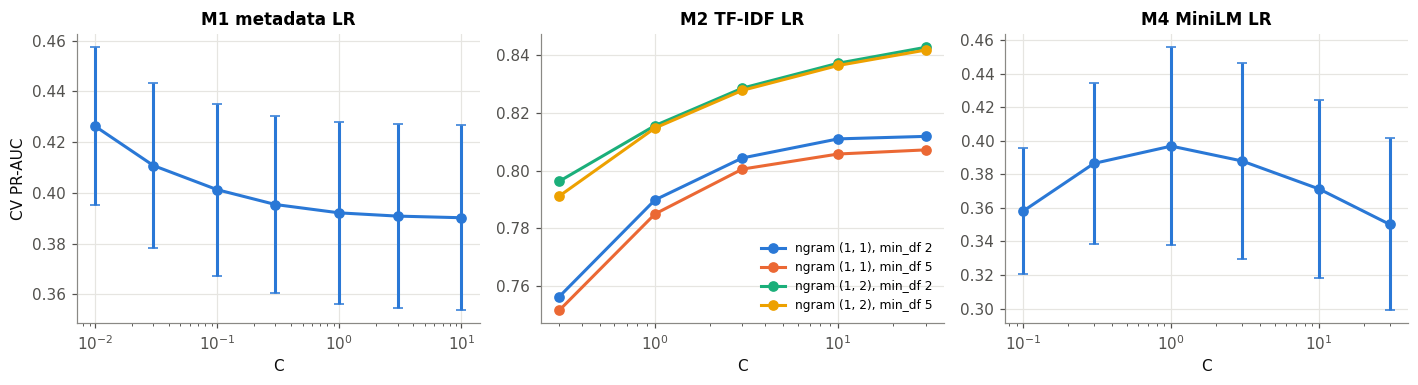

M2 class weights vs oversampling:
                         param_ros  mean_test_score  std_test_score
                       passthrough         0.842595        0.029154
RandomOverSampler(random_state=42)         0.844466        0.030023


In [11]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
r = pd.DataFrame(grids["M1"].cv_results_)
axes[0].errorbar(r.param_clf__C.astype(float), r.mean_test_score, yerr=r.std_test_score, marker="o", ms=6, capsize=3, color=C[0])
axes[0].set(xscale="log", xlabel="C", ylabel="CV PR-AUC", title="M1 metadata LR")
r = pd.DataFrame(grids["M2"].cv_results_)
for i, ((ng, md_), g) in enumerate(r.groupby([r.param_pre__tfidf__ngram_range.astype(str), r.param_pre__tfidf__min_df])):
    axes[1].plot(g.param_clf__C.astype(float), g.mean_test_score, marker="o", ms=6, color=C[i], label=f"ngram {ng}, min_df {md_}")
axes[1].set(xscale="log", xlabel="C", title="M2 TF-IDF LR"); axes[1].legend(fontsize=8)
r = pd.DataFrame(grids["M4"].cv_results_)
axes[2].errorbar(r.param_clf__C.astype(float), r.mean_test_score, yerr=r.std_test_score, marker="o", ms=6, capsize=3, color=C[0])
axes[2].set(xscale="log", xlabel="C", title="M4 MiniLM LR")
plt.tight_layout(); plt.savefig("figures/hparam_sensitivity.png"); plt.show()
print("M2 class weights vs oversampling:")
print(pd.DataFrame(grids["M2-imb"].cv_results_)[["param_ros", "mean_test_score", "std_test_score"]].to_string(index=False))

## 5. Validation thresholds and the final test evaluation
* **Threshold**: chosen on **validation** to maximize fraud-class F1. B1 is binary, so its threshold is 0.5.
* **Model selection**: the "best model", used for error analysis and the demo, is the one with the highest **validation** PR-AUC, not test.
* **Test metrics**: PR-AUC (primary), fraud-class precision / recall / F1 at the validation threshold, recall at ≥ 90% precision, plus accuracy and ROC-AUC for comparison with prior work.
* **Uncertainty**: 95% bootstrap CIs (1,000 resamples of the test set), plus a paired bootstrap for the key model differences.

In [12]:
def proba(m, X): return m.predict_proba(X)[:, 1]

def best_f1_threshold(y, p):
    pr, rc, th = precision_recall_curve(y, p)
    f1 = 2 * pr[:-1] * rc[:-1] / np.clip(pr[:-1] + rc[:-1], 1e-12, None)
    return float(th[np.nanargmax(f1)])

def threshold_for_precision(y, p, target=0.9):
    pr, rc, th = precision_recall_curve(y, p)
    ok = np.where(pr[:-1] >= target)[0]
    return float(th[ok[0]]) if len(ok) else 1.0

def threshold_for_recall(y, p, target=0.9):
    pr, rc, th = precision_recall_curve(y, p)
    ok = np.where(rc[:-1] >= target)[0]
    return float(th[ok[-1]]) if len(ok) else 0.0

def recall_at_precision(y, p, target=0.9):
    pr, rc, _ = precision_recall_curve(y, p)
    ok = pr >= target
    return float(rc[ok].max()) if ok.any() else 0.0

def metrics(y, p, thr):
    yh = (p >= thr).astype(int)
    return {"PR-AUC": average_precision_score(y, p), "ROC-AUC": roc_auc_score(y, p) if len(set(p)) > 1 else 0.5,
            "Precision": precision_score(y, yh, zero_division=0), "Recall": recall_score(y, yh, zero_division=0),
            "F1": f1_score(y, yh, zero_division=0), "Recall@P90": recall_at_precision(y, p),
            "Accuracy": accuracy_score(y, yh)}

rng = np.random.default_rng(SEED)
BOOT = [rng.integers(0, len(yte), len(yte)) for _ in range(1000)]
def boot_ci(y, p, thr, keys=("PR-AUC", "F1")):
    vals = {k: [] for k in keys}
    for b in BOOT:
        if y[b].sum() == 0: continue
        yh = (p[b] >= thr).astype(int)
        if "PR-AUC" in keys: vals["PR-AUC"].append(average_precision_score(y[b], p[b]))
        if "F1" in keys: vals["F1"].append(f1_score(y[b], yh, zero_division=0))
    return {k: (np.percentile(v, 2.5), np.percentile(v, 97.5)) for k, v in vals.items()}

P_va = {n: proba(m, Xva) for n, m in models.items()}
P_te = {n: proba(m, Xte) for n, m in models.items()}
THR = {n: (0.5 if n.startswith(("B0", "B1")) else best_f1_threshold(yva, P_va[n])) for n in models}
THR["B0 Majority"] = 0.5   # always predicts "real"

rows = []
for n in models:
    mv, mt = metrics(yva, P_va[n], THR[n]), metrics(yte, P_te[n], THR[n])
    ci = boot_ci(yte, P_te[n], THR[n])
    rows.append({"model": n, "val PR-AUC": mv["PR-AUC"], "threshold": THR[n], **mt,
                 "PR-AUC 95% CI": f"[{ci['PR-AUC'][0]:.3f}, {ci['PR-AUC'][1]:.3f}]",
                 "F1 95% CI": f"[{ci['F1'][0]:.3f}, {ci['F1'][1]:.3f}]"})
results = pd.DataFrame(rows).set_index("model")
results.to_csv("results/main_test_results.csv")
BEST = results.drop(index=["B0 Majority", "B1 Rule"])["val PR-AUC"].idxmax()
print("Best model by validation PR-AUC:", BEST)
results.round(3)

Best model by validation PR-AUC: M2 LR-tfidf


,val PR-AUC,threshold,PR-AUC,ROC-AUC,Precision,Recall,F1,Recall@P90,Accuracy,PR-AUC 95% CI,F1 95% CI
model,,,,,,,,,,,
B0 Majority,0.044,0.500,0.055,0.500,0.000,0.000,0.000,0.000,0.945,"[0.046, 0.065]","[0.000, 0.000]"
B1 Rule,0.135,0.500,0.151,0.740,0.211,0.614,0.314,0.000,0.851,"[0.117, 0.189]","[0.261, 0.366]"
M1 LR-meta,0.405,0.796,0.464,0.916,0.430,0.630,0.511,0.055,0.933,"[0.382, 0.550]","[0.444, 0.573]"
M2 LR-tfidf,0.907,0.402,0.891,0.989,0.885,0.850,0.867,0.843,0.986,"[0.830, 0.942]","[0.817, 0.909]"
M3 LGBM-meta+text,0.859,0.219,0.866,0.986,0.889,0.756,0.817,0.717,0.981,"[0.809, 0.918]","[0.760, 0.869]"
M4 LR-MiniLM,0.480,0.827,0.443,0.889,0.500,0.488,0.494,0.000,0.945,"[0.352, 0.544]","[0.417, 0.561]"


In [13]:
def paired_boot_diff(a, b, y=yte):
    d = []
    for bi in BOOT:
        if y[bi].sum() == 0: continue
        d.append(average_precision_score(y[bi], P_te[a][bi]) - average_precision_score(y[bi], P_te[b][bi]))
    d = np.array(d)
    return {"A": a, "B": b, "ΔPR-AUC": average_precision_score(y, P_te[a]) - average_precision_score(y, P_te[b]),
            "95% CI": f"[{np.percentile(d, 2.5):.3f}, {np.percentile(d, 97.5):.3f}]", "P(Δ≤0)": float((d <= 0).mean())}

pairs = [("M3 LGBM-meta+text", "M2 LR-tfidf"), ("M3 LGBM-meta+text", "M1 LR-meta"),
         ("M2 LR-tfidf", "M1 LR-meta"), ("M2 LR-tfidf", "M4 LR-MiniLM"), ("M1 LR-meta", "B1 Rule")]
diffs = pd.DataFrame([paired_boot_diff(a, b) for a, b in pairs]); diffs.to_csv("results/paired_differences.csv", index=False)
diffs.round(3)

,A,B,ΔPR-AUC,95% CI,P(Δ≤0)
0,M3 LGBM-meta+text,M2 LR-tfidf,-0.024,"[-0.065, 0.017]",0.892
1,M3 LGBM-meta+text,M1 LR-meta,0.403,"[0.320, 0.482]",0.000
2,M2 LR-tfidf,M1 LR-meta,0.427,"[0.334, 0.520]",0.000
3,M2 LR-tfidf,M4 LR-MiniLM,0.448,"[0.348, 0.536]",0.000
4,M1 LR-meta,B1 Rule,0.313,"[0.245, 0.388]",0.000


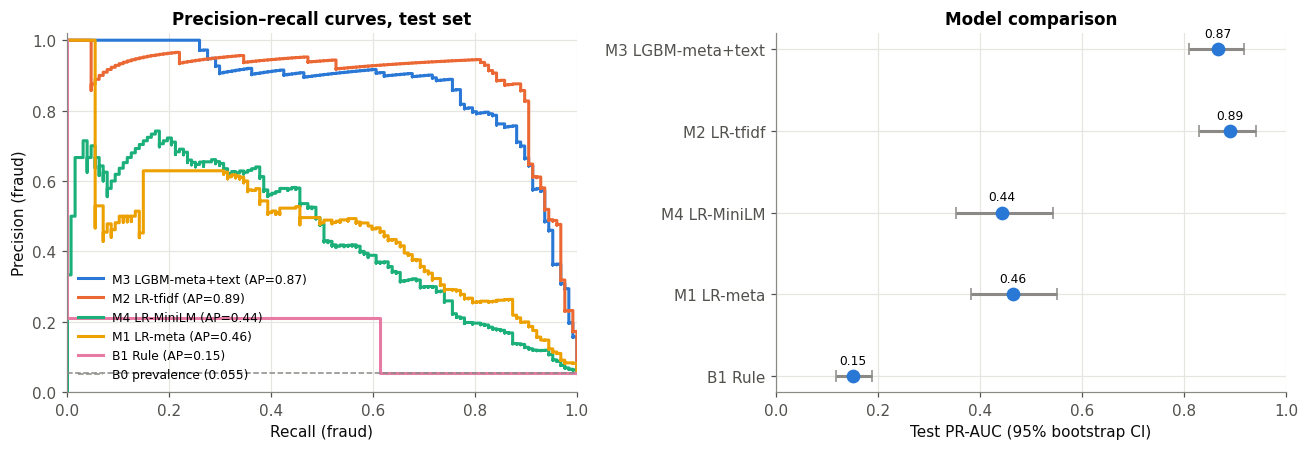

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
order = ["M3 LGBM-meta+text", "M2 LR-tfidf", "M4 LR-MiniLM", "M1 LR-meta", "B1 Rule"]
for i, n in enumerate(order):
    pr, rc, _ = precision_recall_curve(yte, P_te[n])
    axes[0].plot(rc, pr, color=C[i], label=f"{n} (AP={results.loc[n,'PR-AUC']:.2f})", drawstyle="steps-post")
axes[0].axhline(yte.mean(), color=GRAY, ls="--", lw=1, label=f"B0 prevalence ({yte.mean():.3f})")
axes[0].set(xlabel="Recall (fraud)", ylabel="Precision (fraud)", title="Precision–recall curves, test set", xlim=(0, 1), ylim=(0, 1.02))
axes[0].legend(fontsize=8, loc="lower left")

lo = results.loc[order[::-1], "PR-AUC 95% CI"].str.strip("[]").str.split(", ", expand=True).astype(float)
pt = results.loc[order[::-1], "PR-AUC"]
axes[1].errorbar(pt, range(len(pt)), xerr=[pt - lo[0], lo[1] - pt], fmt="o", ms=8, color=C[0], ecolor=GRAY, capsize=4)
axes[1].set_yticks(range(len(pt))); axes[1].set_yticklabels(pt.index)
axes[1].set(xlabel="Test PR-AUC (95% bootstrap CI)", title="Model comparison", xlim=(0, 1))
for yi, v in enumerate(pt): axes[1].annotate(f"{v:.2f}", (v, yi), xytext=(0, 8), textcoords="offset points", ha="center", fontsize=8)
plt.tight_layout(); plt.savefig("figures/pr_curves_and_ci.png"); plt.show()

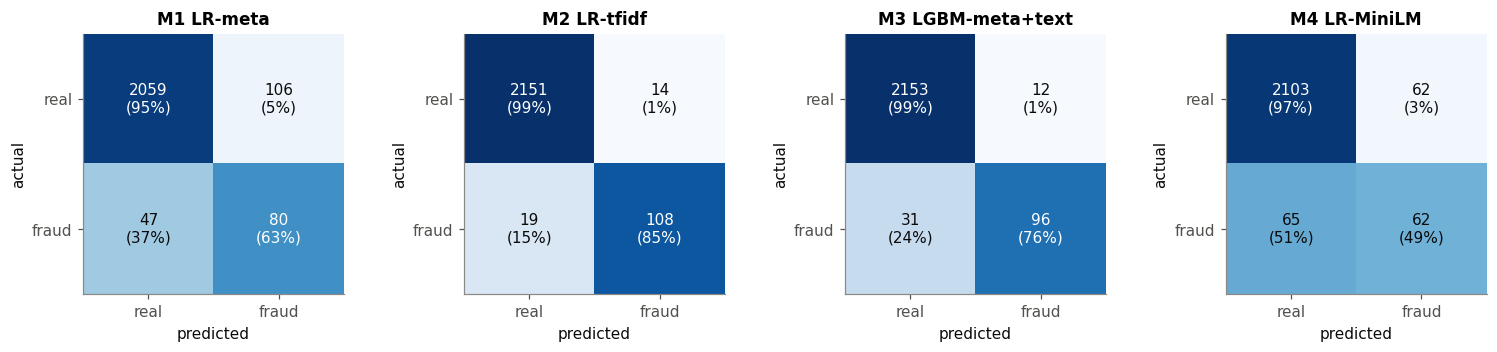

In [15]:
fig, axes = plt.subplots(1, 4, figsize=(14, 3.2))
for ax, n in zip(axes, ["M1 LR-meta", "M2 LR-tfidf", "M3 LGBM-meta+text", "M4 LR-MiniLM"]):
    cm = confusion_matrix(yte, (P_te[n] >= THR[n]).astype(int))
    rate = cm / cm.sum(1, keepdims=True)          # color = row-normalized rate
    ax.imshow(rate, cmap="Blues", vmin=0, vmax=1)
    for (i, j), v in np.ndenumerate(cm):
        ax.text(j, i, f"{v}\n({rate[i, j]:.0%})", ha="center", va="center", fontsize=10,
                color="white" if rate[i, j] > 0.6 else "#0b0b0b")
    ax.set(xticks=[0, 1], yticks=[0, 1], xticklabels=["real", "fraud"], yticklabels=["real", "fraud"],
           xlabel="predicted", ylabel="actual", title=n); ax.grid(False)
plt.tight_layout(); plt.savefig("figures/confusion_matrices.png"); plt.show()

## 6. RQ1: feature ablation and attribution
**Ablation**: M3 is retrained and **re-tuned** with `has_company_logo`, `miss_company_profile`, and the company-profile text all removed, so the comparison is fair. All three have to go, because the profile text alone reveals whether a profile exists.

In [16]:
m3a_best, m3a_cv = tune_m3(Xtr, ytr, gtr, drop_shortcuts=True, tag="M3-noshortcut")
models["M3 no logo/profile"] = m3_pipeline(m3a_best, drop_shortcuts=True).fit(Xtr, ytr)
n = "M3 no logo/profile"
P_va[n], P_te[n] = proba(models[n], Xva), proba(models[n], Xte)
THR[n] = best_f1_threshold(yva, P_va[n])
ci = boot_ci(yte, P_te[n], THR[n])
results.loc[n] = {"val PR-AUC": average_precision_score(yva, P_va[n]), "threshold": THR[n], **metrics(yte, P_te[n], THR[n]),
                  "PR-AUC 95% CI": f"[{ci['PR-AUC'][0]:.3f}, {ci['PR-AUC'][1]:.3f}]", "F1 95% CI": f"[{ci['F1'][0]:.3f}, {ci['F1'][1]:.3f}]"}
results.to_csv("results/main_test_results.csv")
abl = pd.DataFrame([paired_boot_diff("M3 LGBM-meta+text", n)])
display(results.loc[["M3 LGBM-meta+text", n], ["PR-AUC", "PR-AUC 95% CI", "F1", "Recall@P90"]].round(3)); abl.round(3)

  M3-noshortcut: cached fold transforms in 203s
M3-noshortcut: best CV PR-AUC = 0.722 | {'n_estimators': 600, 'learning_rate': 0.1, 'num_leaves': 15, 'imb': 'ros'} | 533s


,PR-AUC,PR-AUC 95% CI,F1,Recall@P90
model,,,,
M3 LGBM-meta+text,0.866,"[0.809, 0.918]",0.817,0.717
M3 no logo/profile,0.802,"[0.737, 0.861]",0.739,0.449


,A,B,ΔPR-AUC,95% CI,P(Δ≤0)
0,M3 LGBM-meta+text,M3 no logo/profile,0.064,"[0.021, 0.110]",0.003


**Logistic regression coefficients** (on standardized metadata for M1, TF-IDF for M2)

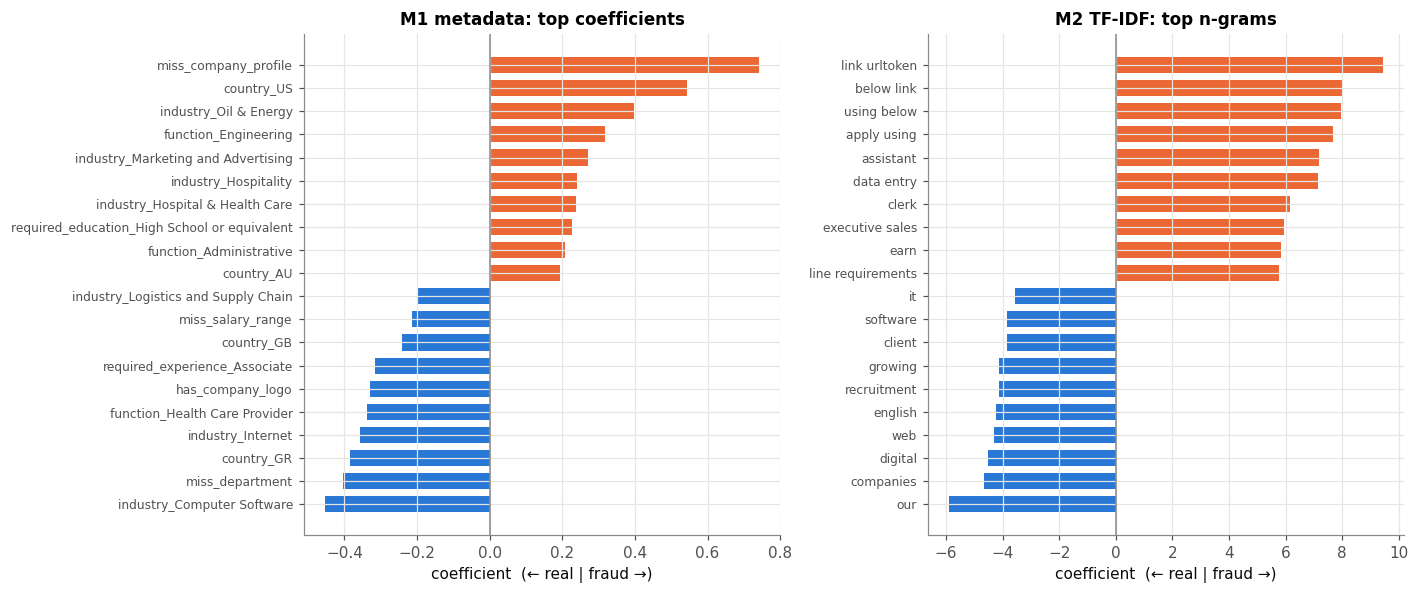

In [17]:
m1p = models["M1 LR-meta"]
names1 = m1p.named_steps["pre"].get_feature_names_out()
coef1 = pd.Series(m1p.named_steps["clf"].coef_[0], index=[s.split("__", 1)[1] for s in names1]).sort_values()
m2p = models["M2 LR-tfidf"]
names2 = m2p.named_steps["pre"].get_feature_names_out()
coef2 = pd.Series(m2p.named_steps["clf"].coef_[0], index=[s.split("__", 1)[1] for s in names2]).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
for ax, coef, title in [(axes[0], coef1, "M1 metadata: top coefficients"), (axes[1], coef2, "M2 TF-IDF: top n-grams")]:
    top = pd.concat([coef.head(10), coef.tail(10)])
    ax.barh(range(len(top)), top.values, color=[C[0] if v < 0 else C[1] for v in top.values], height=0.7)
    ax.set_yticks(range(len(top))); ax.set_yticklabels(top.index, fontsize=8)
    ax.axvline(0, color=GRAY, lw=1); ax.set(title=title, xlabel="coefficient  (← real | fraud →)")
plt.tight_layout(); plt.savefig("figures/lr_coefficients.png"); plt.show()
pd.DataFrame({"M1 → fraud": coef1.tail(10)[::-1].index, "M1 → real": coef1.head(10).index,
              "M2 → fraud": coef2.tail(10)[::-1].index, "M2 → real": coef2.head(10).index}).to_csv("results/top_coefficients.csv", index=False)

**SHAP for M3** (Lundberg & Lee, 2017). TreeExplainer runs on the test set. The 300 SVD components are not interpretable one by one, so I also add up |SHAP| by feature *group* (shortcut flags / other metadata / text) to see how much of the model's attribution comes from the shortcuts.

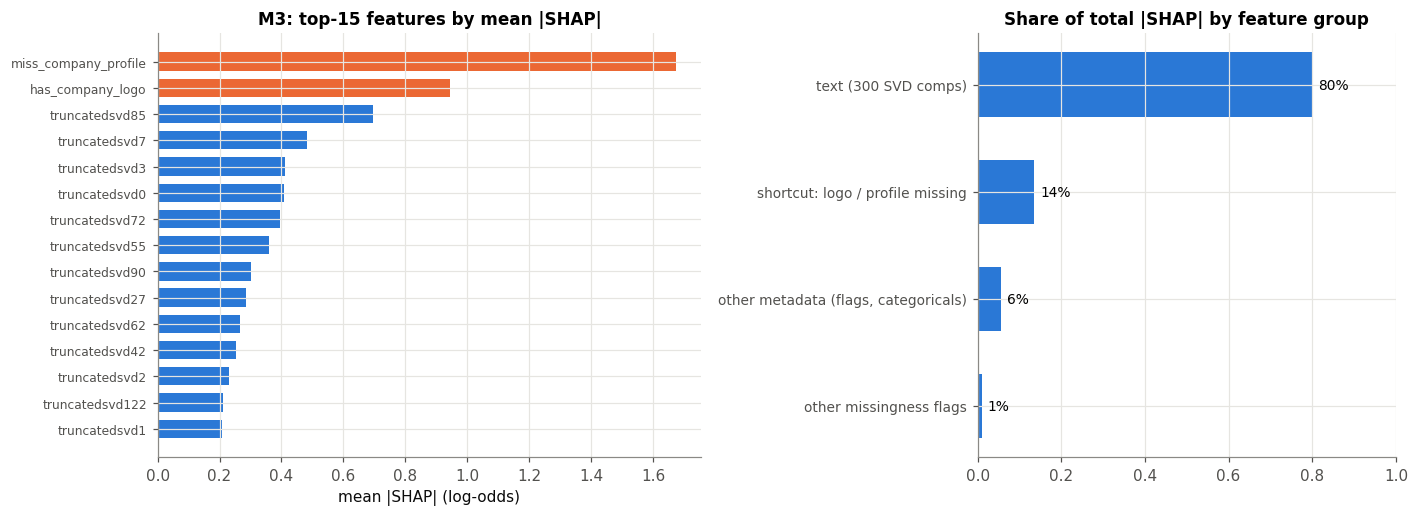

other missingness flags                 0.010
other metadata (flags, categoricals)    0.056
shortcut: logo / profile missing        0.135
text (300 SVD comps)                    0.799
dtype: float64

In [18]:
m3p = models["M3 LGBM-meta+text"]
Xte_m3 = m3p.named_steps["pre"].transform(Xte)
fn3 = m3p.named_steps["pre"].get_feature_names_out()
sv = shap.TreeExplainer(m3p.named_steps["clf"]).shap_values(Xte_m3)
sv = sv[1] if isinstance(sv, list) else sv
mean_abs = pd.Series(np.abs(sv).mean(0), index=fn3)

def group_of(f):
    if f in ("bin__has_company_logo", "bin__miss_company_profile"): return "shortcut: logo / profile missing"
    if f.startswith("txt__"): return "text (300 SVD comps)"
    if f.startswith("bin__miss_"): return "other missingness flags"
    return "other metadata (flags, categoricals)"
grp = mean_abs.groupby(mean_abs.index.map(group_of)).sum().sort_values()
share = (grp / grp.sum()).round(3)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={"width_ratios": [1.3, 1]})
top = mean_abs.sort_values().tail(15)
axes[0].barh(range(15), top.values, color=[C[1] if group_of(f).startswith("shortcut") else (C[0] if f.startswith("txt") else C[2]) for f in top.index], height=0.7)
axes[0].set_yticks(range(15)); axes[0].set_yticklabels([f.split("__", 1)[1] for f in top.index], fontsize=8)
axes[0].set(title="M3: top-15 features by mean |SHAP|", xlabel="mean |SHAP| (log-odds)")
axes[1].barh(range(len(share)), share.values, color=C[0], height=0.6)
axes[1].set_yticks(range(len(share))); axes[1].set_yticklabels(share.index, fontsize=9)
for i, v in enumerate(share.values): axes[1].annotate(f"{v:.0%}", (v, i), xytext=(4, 0), textcoords="offset points", va="center", fontsize=9)
axes[1].set(title="Share of total |SHAP| by feature group", xlim=(0, 1))
plt.tight_layout(); plt.savefig("figures/shap_m3.png"); plt.show()
share.to_csv("results/shap_group_share.csv"); share

## 7. RQ1: counterfactual "dress-up" test
For every **fraud ad in the test set**, I simulate a scammer who adds a logo and/or pastes in a company profile. The profile is **sampled from legitimate *training* ads**, so no test information leaks. The modified ads go back through `build_features` and each fitted model. Reported per model:
* **flip rate**: the share of fraud ads the model *caught* at its validation threshold that it no longer flags;
* **mean drop in P(fraud)** over all test fraud ads.

Three variants separate the two cues: logo only, profile only, both. As the **reverse test** (the harm to small, legitimate employers), I take real test ads that *have* a logo and profile, remove both, and count how many become newly flagged. B1 is left out, since by construction it flips 100%.

In [19]:
rng_cf = np.random.default_rng(SEED)
legit_profiles = df.iloc[train_idx].query("fraudulent == 0")["company_profile"].dropna()
legit_profiles = legit_profiles[legit_profiles.str.len() > 100].to_numpy()

raw_te = df.iloc[test_idx]
fraud_raw = raw_te[raw_te.fraudulent == 1].copy()
sampled = rng_cf.choice(legit_profiles, size=len(fraud_raw), replace=True)

def dress(d, logo, profile):
    d = d.copy()
    if logo: d["has_company_logo"] = 1
    if profile: d["company_profile"] = sampled[:len(d)]
    return d

CF_MODELS = ["M1 LR-meta", "M2 LR-tfidf", "M3 LGBM-meta+text", "M3 no logo/profile", "M4 LR-MiniLM"]
X_fraud = build_features(fraud_raw)
cf_rows = []
for variant, (lg, pf) in {"logo only": (1, 0), "profile only": (0, 1), "logo + profile": (1, 1)}.items():
    Xcf = build_features(dress(fraud_raw, lg, pf))
    for n in CF_MODELS:
        p0, p1 = proba(models[n], X_fraud), proba(models[n], Xcf)
        caught = p0 >= THR[n]
        cf_rows.append({"variant": variant, "model": n, "caught before": int(caught.sum()),
                        "caught after": int((p1 >= THR[n]).sum()),
                        "flip rate (of caught)": float(((p1 < THR[n]) & caught).sum() / max(caught.sum(), 1)),
                        "mean ΔP(fraud)": float((p1 - p0).mean())})
cf = pd.DataFrame(cf_rows); cf.to_csv("results/counterfactual_fraud.csv", index=False)
joblib.dump(EMB, EMB_PATH)
cf.pivot(index="model", columns="variant", values="flip rate (of caught)").loc[CF_MODELS].round(3)

variant,logo + profile,logo only,profile only
model,,,
M1 LR-meta,0.700,0.250,0.625
M2 LR-tfidf,0.750,0.000,0.750
M3 LGBM-meta+text,0.896,0.417,0.885
M3 no logo/profile,0.000,0.000,0.000
M4 LR-MiniLM,0.565,0.000,0.565


In [20]:
# Reverse test: strip logo and profile from real ads that had both
real_raw = raw_te[(raw_te.fraudulent == 0) & (raw_te.has_company_logo == 1) & raw_te.company_profile.notna()].copy()
X_real = build_features(real_raw)
real_strip = real_raw.copy(); real_strip["has_company_logo"] = 0; real_strip["company_profile"] = np.nan
X_real_s = build_features(real_strip)
rev = []
for n in CF_MODELS:
    p0, p1 = proba(models[n], X_real), proba(models[n], X_real_s)
    rev.append({"model": n, "real ads": len(real_raw), "false positives before": int((p0 >= THR[n]).sum()),
                "false positives after": int((p1 >= THR[n]).sum()),
                "newly flagged per 1,000": 1000 * float(((p1 >= THR[n]) & (p0 < THR[n])).mean())})
rev = pd.DataFrame(rev).set_index("model"); rev.to_csv("results/counterfactual_real_stripped.csv"); rev.round(1)

Batches: 100%|██████████| 26/26 [00:06<00:00,  4.12it/s]


,real ads,false positives before,false positives after,"newly flagged per 1,000"
model,,,,
M1 LR-meta,1672,22,449,255.4
M2 LR-tfidf,1672,1,12,6.6
M3 LGBM-meta+text,1672,0,41,24.5
M3 no logo/profile,1672,4,4,0.0
M4 LR-MiniLM,1672,33,48,10.2


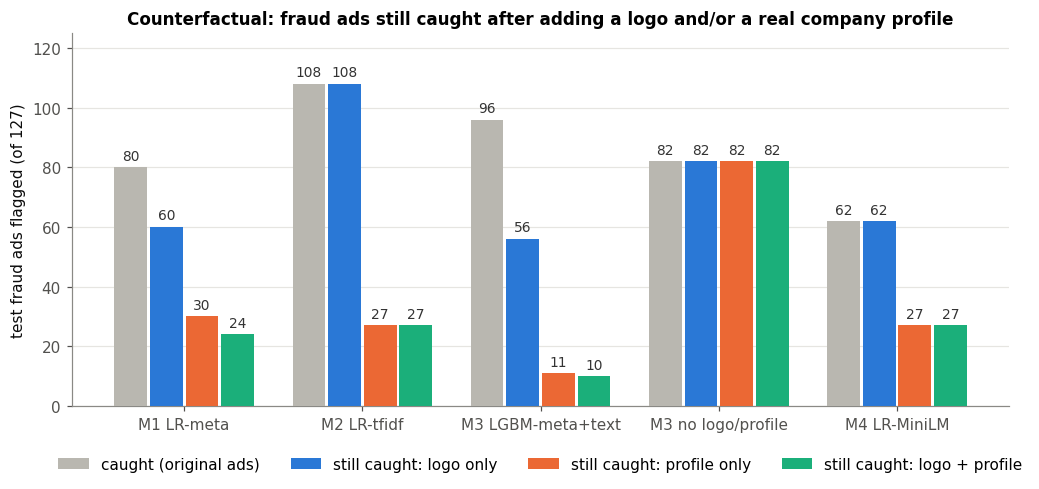

In [21]:
ORDER = ["logo only", "profile only", "logo + profile"]
before = cf[cf.variant == "logo only"].set_index("model")["caught before"].loc[CF_MODELS]
after = cf.pivot(index="model", columns="variant", values="caught after").loc[CF_MODELS][ORDER]
series = [("caught (original ads)", before, "#b9b7b0")] + [(f"still caught: {v}", after[v], C[i]) for i, v in enumerate(ORDER)]
fig, ax = plt.subplots(figsize=(11, 4.4))
w, x = 0.2, np.arange(len(CF_MODELS))
for i, (lab, vals, col) in enumerate(series):
    xs = x + (i - 1.5) * w
    ax.bar(xs, vals, width=w * 0.92, color=col, label=lab, zorder=3)
    for xi, v in zip(xs, vals):
        ax.text(xi, v + 1.5, str(int(v)), ha="center", va="bottom", fontsize=9, color="#333")
ax.set_xticks(x); ax.set_xticklabels(CF_MODELS)
ax.grid(axis="x", visible=False)
ax.set(ylabel=f"test fraud ads flagged (of {len(fraud_raw)})", ylim=(0, 125),
       title="Counterfactual: fraud ads still caught after adding a logo and/or a real company profile")
ax.legend(ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.1), fontsize=10)
plt.savefig("figures/counterfactual_counts.png"); plt.show()

## 8. RQ2: distribution shift
Each model is refit with its **main-split hyperparameters** (no re-tuning, see limitations) on one slice of the data and scored on a slice it never saw:
* **Region**: train on non-US, test on US, and the reverse. Ads with no country are left out.
* **Industry**: hold out a coarse **health and finance** sector (Hospital & Health Care; Health, Wellness & Fitness; Financial Services; Accounting; Insurance). It has enough fraud (137 ads after dedup) to measure, and unlike Oil & Energy it is not dominated by one apparent scam campaign.

Leakage: any training ad that shares a near-duplicate group with the held-out slice is removed.

**Reading the numbers**: PR-AUC depends on prevalence, and prevalence differs a lot between slices (US ≈ 7% fraud, non-US ≈ 2%). So the table reports each slice's prevalence, uses **ROC-AUC (prevalence-free)** as the main shift comparison, and gives an **in-distribution reference**: the main-split models scored on the same subgroup of the main test set.

In [22]:
SHIFT_MODELS = ["M1 LR-meta", "M2 LR-tfidf", "M3 LGBM-meta+text", "M3 no logo/profile", "M4 LR-MiniLM"]
country = X_all["country"]
HEALTH_FIN = ["Hospital & Health Care", "Health, Wellness and Fitness", "Financial Services", "Accounting", "Insurance"]
shifts = {
    "train non-US → test US": (country.ne("US") & country.ne("missing"), country.eq("US")),
    "train US → test non-US": (country.eq("US"), country.ne("US") & country.ne("missing")),
    "industry hold-out: health & finance": (~df["industry"].isin(HEALTH_FIN), df["industry"].isin(HEALTH_FIN)),
}
shift_rows = []
for sname, (tr_mask, te_mask) in shifts.items():
    te_i = np.where(te_mask)[0]
    tr_i = np.where(tr_mask & ~pd.Series(groups_all).isin(set(groups_all[te_i])))[0]
    for n in SHIFT_MODELS:
        t0 = time.time()
        m = clone(models[n])   # same pipeline + hyperparameters, unfitted
        m.fit(X_all.iloc[tr_i], y_all[tr_i])
        p = proba(m, X_all.iloc[te_i]); y = y_all[te_i]
        shift_rows.append({"shift": sname, "model": n, "train ads": len(tr_i), "train fraud": int(y_all[tr_i].sum()),
                           "test ads": len(te_i), "test fraud": int(y.sum()), "test prevalence": y.mean(),
                           "PR-AUC": average_precision_score(y, p), "ROC-AUC": roc_auc_score(y, p)})
        print(f"{sname:38s} {n:22s} PR-AUC={shift_rows[-1]['PR-AUC']:.3f} ROC-AUC={shift_rows[-1]['ROC-AUC']:.3f} ({time.time()-t0:.0f}s)")
shift_df = pd.DataFrame(shift_rows)

train non-US → test US                 M1 LR-meta             PR-AUC=0.255 ROC-AUC=0.796 (0s)
train non-US → test US                 M2 LR-tfidf            PR-AUC=0.419 ROC-AUC=0.798 (9s)
train non-US → test US                 M3 LGBM-meta+text      PR-AUC=0.339 ROC-AUC=0.803 (42s)
train non-US → test US                 M3 no logo/profile     PR-AUC=0.193 ROC-AUC=0.667 (32s)
train non-US → test US                 M4 LR-MiniLM           PR-AUC=0.242 ROC-AUC=0.704 (0s)
train US → test non-US                 M1 LR-meta             PR-AUC=0.113 ROC-AUC=0.811 (0s)
train US → test non-US                 M2 LR-tfidf            PR-AUC=0.494 ROC-AUC=0.918 (10s)
train US → test non-US                 M3 LGBM-meta+text      PR-AUC=0.528 ROC-AUC=0.942 (51s)
train US → test non-US                 M3 no logo/profile     PR-AUC=0.377 ROC-AUC=0.856 (41s)
train US → test non-US                 M4 LR-MiniLM           PR-AUC=0.286 ROC-AUC=0.841 (0s)
industry hold-out: health & finance    M1 LR-meta      

In [23]:
# In-distribution reference: main models scored on the same subgroup of the *main* test set
ref_masks = {"train non-US → test US": Xte["country"].eq("US").to_numpy(),
             "train US → test non-US": (Xte["country"].ne("US") & Xte["country"].ne("missing")).to_numpy(),
             "industry hold-out: health & finance": df.iloc[test_idx]["industry"].isin(HEALTH_FIN).to_numpy()}
ref = []
for sname, mk in ref_masks.items():
    for n in SHIFT_MODELS:
        y, p = yte[mk], P_te[n][mk]
        ref.append({"shift": sname, "model": n, "in-dist test fraud": int(y.sum()),
                    "in-dist PR-AUC": average_precision_score(y, p), "in-dist ROC-AUC": roc_auc_score(y, p)})
shift_df = shift_df.merge(pd.DataFrame(ref), on=["shift", "model"])
shift_df["ΔROC-AUC (shift − in-dist)"] = shift_df["ROC-AUC"] - shift_df["in-dist ROC-AUC"]
shift_df.to_csv("results/distribution_shift.csv", index=False)
shift_df[["shift", "model", "train fraud", "test fraud", "test prevalence", "PR-AUC", "in-dist PR-AUC",
          "ROC-AUC", "in-dist ROC-AUC", "ΔROC-AUC (shift − in-dist)", "in-dist test fraud"]].round(3)

,shift,model,train fraud,test fraud,test prevalence,PR-AUC,in-dist PR-AUC,ROC-AUC,in-dist ROC-AUC,ΔROC-AUC (shift − in-dist),in-dist test fraud
0,train non-US → test US,M1 LR-meta,103,597,0.066,0.255,0.497,0.796,0.887,-0.091,113
1,train non-US → test US,M2 LR-tfidf,103,597,0.066,0.419,0.903,0.798,0.987,-0.189,113
2,train non-US → test US,M3 LGBM-meta+text,103,597,0.066,0.339,0.887,0.803,0.982,-0.180,113
3,train non-US → test US,M3 no logo/profile,103,597,0.066,0.193,0.826,0.667,0.942,-0.275,113
4,train non-US → test US,M4 LR-MiniLM,103,597,0.066,0.242,0.487,0.704,0.859,-0.155,113
5,train US → test non-US,M1 LR-meta,596,105,0.016,0.113,0.350,0.811,0.947,-0.136,14
6,train US → test non-US,M2 LR-tfidf,596,105,0.016,0.494,0.760,0.918,0.990,-0.072,14
7,train US → test non-US,M3 LGBM-meta+text,596,105,0.016,0.528,0.728,0.942,0.993,-0.052,14
8,train US → test non-US,M3 no logo/profile,596,105,0.016,0.377,0.650,0.856,0.969,-0.113,14
9,train US → test non-US,M4 LR-MiniLM,596,105,0.016,0.286,0.232,0.841,0.915,-0.074,14


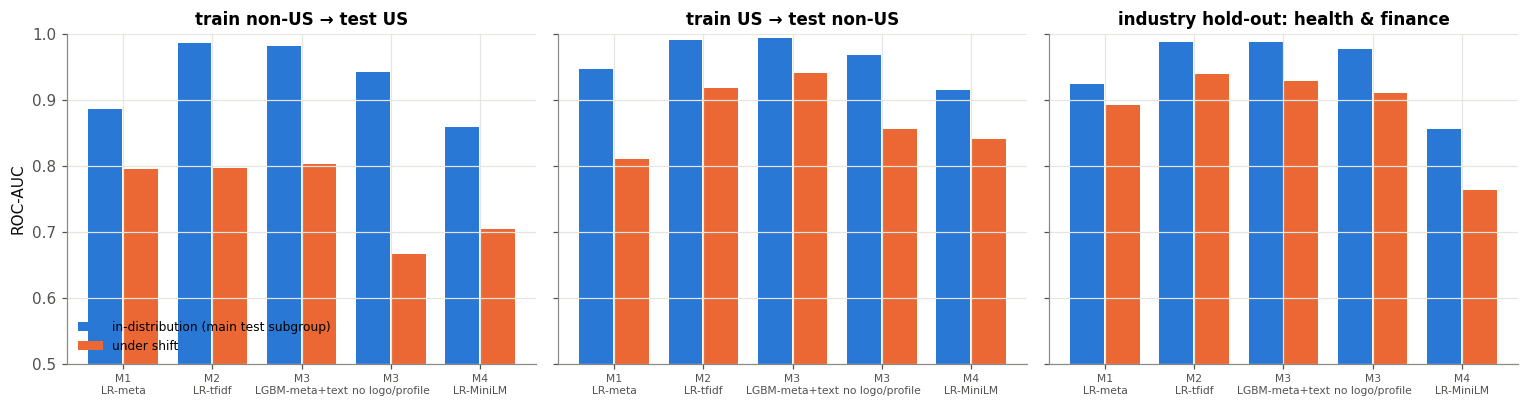

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), sharey=True)
for ax, (sname, g) in zip(axes, shift_df.groupby("shift", sort=False)):
    x = np.arange(len(g))
    ax.bar(x - 0.2, g["in-dist ROC-AUC"], 0.38, color=C[0], label="in-distribution (main test subgroup)")
    ax.bar(x + 0.2, g["ROC-AUC"], 0.38, color=C[1], label="under shift")
    ax.set_xticks(x); ax.set_xticklabels([m.replace(" ", "\n", 1) for m in g["model"]], fontsize=7)
    ax.set(title=sname, ylim=(0.5, 1.0))
axes[0].set_ylabel("ROC-AUC"); axes[0].legend(fontsize=8, loc="lower left")
plt.tight_layout(); plt.savefig("figures/distribution_shift.png"); plt.show()

## 9. RQ3: threshold sensitivity
A moderator has to review every flagged ad, so the operating point matters. For the best model and M2, I plot precision, recall, and **ads flagged per 1,000** against the threshold on the test set. Three operating points are **chosen on validation** and then evaluated on test:
* **lenient**: recall ≥ 90% on validation (catch nearly all scams; more reviews);
* **balanced**: maximum F1 on validation;
* **strict**: precision ≥ 90% on validation (few false alarms).

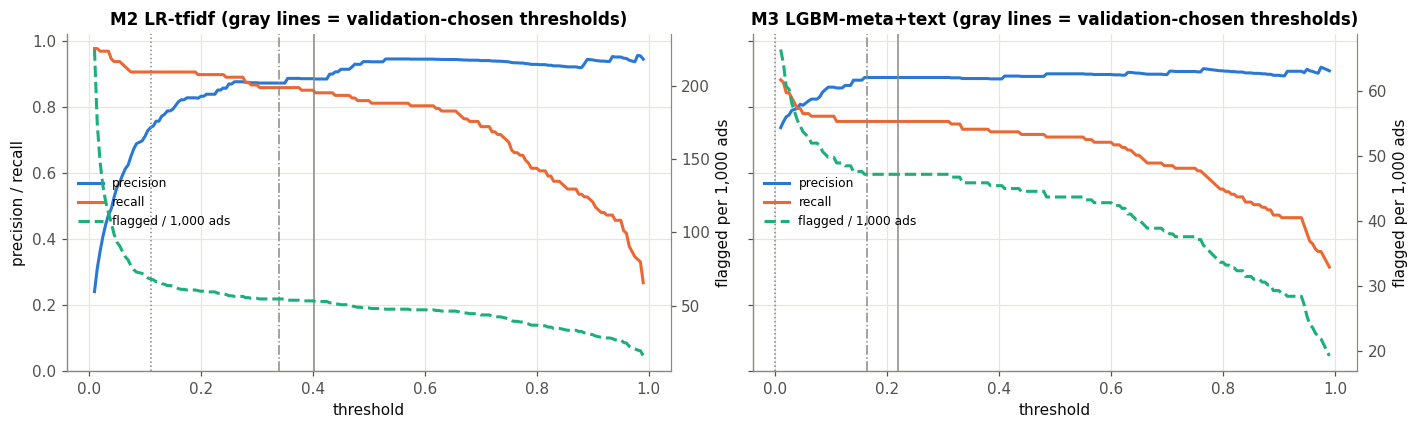

,model,operating point,threshold,test precision,test recall,"flagged per 1,000",fraud caught,fraud missed,false alarms
0,M2 LR-tfidf,lenient (val R≥0.9),0.111,0.737,0.906,68.063,115,12,41
1,M2 LR-tfidf,balanced (val max F1),0.402,0.885,0.850,53.229,108,19,14
2,M2 LR-tfidf,strict (val P≥0.9),0.339,0.872,0.858,54.538,109,18,16
3,M3 LGBM-meta+text,lenient (val R≥0.9),0.000,0.440,0.953,119.983,121,6,154
4,M3 LGBM-meta+text,balanced (val max F1),0.219,0.889,0.756,47.120,96,31,12
5,M3 LGBM-meta+text,strict (val P≥0.9),0.163,0.889,0.756,47.120,96,31,12


In [25]:
op_rows = []
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, n in zip(axes, [BEST, "M2 LR-tfidf" if BEST != "M2 LR-tfidf" else "M3 LGBM-meta+text"]):
    ths = np.linspace(0.01, 0.99, 197)
    p = P_te[n]
    prec = [precision_score(yte, p >= t, zero_division=1) for t in ths]
    rec = [recall_score(yte, p >= t) for t in ths]
    flag = [1000 * (p >= t).mean() for t in ths]
    ax.plot(ths, prec, color=C[0], label="precision"); ax.plot(ths, rec, color=C[1], label="recall")
    ax2 = ax.twinx(); ax2.plot(ths, flag, color=C[2], ls="--", label="flagged / 1,000 ads"); ax2.set_ylabel("flagged per 1,000 ads")
    ax2.spines["right"].set_visible(True); ax2.grid(False)
    ops = {"lenient (val R≥0.9)": threshold_for_recall(yva, P_va[n], 0.9), "balanced (val max F1)": THR[n],
           "strict (val P≥0.9)": threshold_for_precision(yva, P_va[n], 0.9)}
    for (lab, t), ls in zip(ops.items(), [":", "-", "-."]):
        ax.axvline(t, color=GRAY, ls=ls, lw=1)
        yh = p >= t
        op_rows.append({"model": n, "operating point": lab, "threshold": t,
                        "test precision": precision_score(yte, yh, zero_division=0), "test recall": recall_score(yte, yh),
                        "flagged per 1,000": 1000 * yh.mean(), "fraud caught": int((yh & (yte == 1)).sum()),
                        "fraud missed": int((~yh & (yte == 1)).sum()), "false alarms": int((yh & (yte == 0)).sum())})
    ax.set(title=f"{n} (gray lines = validation-chosen thresholds)", xlabel="threshold", ylim=(0, 1.02))
    h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels(); ax.legend(h1 + h2, l1 + l2, fontsize=8, loc="center left")
axes[0].set_ylabel("precision / recall")
plt.tight_layout(); plt.savefig("figures/threshold_sensitivity.png"); plt.show()
ops_df = pd.DataFrame(op_rows); ops_df.to_csv("results/operating_points.csv", index=False); ops_df.round(3)

## 10. RQ3: error analysis
Errors of the **best model** (chosen on validation PR-AUC) at its balanced threshold. First, a quantitative look: how do the shortcut features vary across TP / FP / FN / TN? Then up to 30 false positives and 30 false negatives (random sample, seeded; this run has only 14 FP and 19 FN, so all 33 are exported) are exported to `results/error_analysis_to_label.csv`, with an empty `category` column for **hand labeling** (suggested categories: sparse real employer, well-written scam, possible label error, short/vague ad, non-English, other).

In [26]:
pb = P_te[BEST]; yh = (pb >= THR[BEST]).astype(int)
outcome = np.select([(yh == 1) & (yte == 1), (yh == 1) & (yte == 0), (yh == 0) & (yte == 1)], ["TP", "FP", "FN"], "TN")
ea = Xte[["has_company_logo", "miss_company_profile", "miss_salary_range", "telecommuting", "country"]].copy()
ea["outcome"] = outcome; ea["US"] = (ea.country == "US").astype(int)
ea["words"] = Xte["text_all"].str.split().str.len()
summary = ea.groupby("outcome").agg(n=("US", "size"), has_logo=("has_company_logo", "mean"), no_profile=("miss_company_profile", "mean"),
                                    no_salary=("miss_salary_range", "mean"), US=("US", "mean"), median_words=("words", "median")).reindex(["TP", "FN", "FP", "TN"])
summary.to_csv("results/error_outcome_profile.csv"); display(summary.round(3))

rng_e = np.random.default_rng(SEED)
take = lambda idx: rng_e.choice(idx, size=min(30, len(idx)), replace=False)
sel = np.r_[take(np.where(outcome == "FP")[0]), take(np.where(outcome == "FN")[0])]
r = df.iloc[test_idx].iloc[sel]
export = pd.DataFrame({"job_id": r.job_id.values, "error": outcome[sel], "p_fraud": pb[sel].round(3),
                       "title": r.title.values, "location": r.location.values, "has_logo": r.has_company_logo.values,
                       "has_profile": r.company_profile.notna().values, "industry": r.industry.values,
                       "text_snippet": Xte["text_all"].iloc[sel].str[:600].values, "category": "", "notes": ""})
export.to_csv("results/error_analysis_to_label.csv", index=False)
print(f"exported {len(export)} errors ({(export.error=='FP').sum()} FP, {(export.error=='FN').sum()} FN)")
export.head(5)

,n,has_logo,no_profile,no_salary,US,median_words
outcome,,,,,,
TP,108,0.370,0.639,0.750,0.917,199.5
FN,19,0.211,0.684,0.526,0.737,231.0
FP,14,0.214,0.857,0.714,0.571,169.0
TN,2151,0.819,0.173,0.838,0.547,376.0


exported 33 errors (14 FP, 19 FN)


,job_id,error,p_fraud,title,location,has_logo,has_profile,industry,text_snippet,category,notes
0,8194,FP,0.975,Accounting Clerk $15/hr,"US, TX, San Antonio",0,False,Accounting,accounting clerk $15/hr the accounting clerk ...,,
1,16639,FP,0.429,Immediate Opening : Help Desk /Technical Suppo...,"QA, , Doha",1,True,NaN,immediate opening : help desk /technical suppo...,,
2,17868,FP,0.427,Admin Assistant,"GB, WSX, Chichester",1,False,Human Resources,admin assistant we are seeking an administrat...,,
3,11876,FP,0.469,Office Manager / Accounts Position,"IE, L, Dublin",0,False,NaN,office manager / accounts position for progre...,,
4,38,FP,0.471,PROJECT MANAGER,"US, TX, HOUSTON",0,False,Oil & Energy,project manager we are looking for a project ...,,


In [27]:
# After hand-labeling the 'category' column in results/error_analysis_to_label.csv, re-run this cell
lab = pd.read_csv("results/error_analysis_to_label.csv")
if lab["category"].notna().any() and (lab["category"].astype(str).str.strip() != "").any():
    display(pd.crosstab(lab["category"], lab["error"]))
else:
    print("No categories labeled yet. Fill in the 'category' column, then re-run this cell.")

No categories labeled yet. Fill in the 'category' column, then re-run this cell.


## Save models for the demo

In [28]:
joblib.dump({"model": models[BEST], "threshold": THR[BEST], "name": BEST,
             "build_features": "see notebook: build_features()"}, "models/best_model.joblib")
joblib.dump({"model": models["M2 LR-tfidf"], "threshold": THR["M2 LR-tfidf"]}, "models/m2_tfidf.joblib")
json.dump({"best_model": BEST, "thresholds": THR, "m3_params": m3_best, "m3_noshortcut_params": m3a_best,
           "m1_params": grids["M1"].best_params_, "m2_params": {k: str(v) for k, v in grids["M2-imb"].best_params_.items()},
           "m4_params": grids["M4"].best_params_}, open("results/chosen_hyperparameters.json", "w"), indent=2, default=str)
print("saved models/best_model.joblib and results/chosen_hyperparameters.json")

saved models/best_model.joblib and results/chosen_hyperparameters.json


## 11. Changes from the proposal
| Proposal | Implemented | Why |
|---|---|---|
| Group duplicates by a normalized-text hash | Drop exact duplicates, **and** group near-duplicates by normalized-description hash | Keeps test metrics from counting the same ad many times, and also catches reposts with small edits |
| Concatenate text fields *with field markers* | No markers | Markers on non-empty fields would leak the "missing profile" shortcut into the text-only model |
| Tune TF-IDF n-grams / min_df for M3 too | M3 reuses M2's tuned TF-IDF settings; LightGBM grid tuned on per-fold cached TF-IDF+SVD | Compute: refitting TF-IDF+SVD for every LightGBM grid point is wasteful; the result is still leakage-safe |
| Oversampling "tried" for M2 and M3 | Compared to class weights as a tuned option (inside the pipeline) | Makes it a selection decision rather than a side experiment |
| Shift experiments | Main hyperparameters reused, no re-tuning per shift; ROC-AUC + prevalence reported alongside PR-AUC | PR-AUC is not comparable across slices with different fraud rates |
| M4 on full text | Encoder window is 256 tokens; content fields placed first | Keeps the ad body within the encoder's window |
| Streamlit demo | Best model saved to `models/` for the demo | Demo built separately |

## 12. Limitations to discuss in the report
* Only 127 fraud ads in the test set (2,292 ads), so CIs are wide; differences inside overlapping CIs are not claimed.
* Labels come from the platform's own review (missed scams are labeled "real"), and the ads are from 2012–2014.
* Counterfactual profiles are sampled from real ads, so they may not match the ad's industry. A real scammer could write a better-matched one, which makes this a *lower bound* on fragility.
* Shift experiments reuse the in-distribution hyperparameters, and non-US fraud is scarce (103 fraud ads to train on for non-US → US; the in-distribution non-US reference has only 14).
* Other easy-to-fake metadata (salary missing, telecommuting, missing benefits) also carry signal and were not ablated individually.